In [1]:
from google.colab import drive
drive.mount('/content/drive')
# !pip install torchmetrics
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import re
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
import numpy as np
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import pickle
import os
import math

# pd.set_option('display.max_rows', None)

# Load the Excel file (replace with your filename)
file_path = "/content/drive/My Drive/Deep Learning Project/1ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv"
df = pd.read_csv(file_path)

Mounted at /content/drive


In [2]:
# Use GPU if available, else use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [3]:
def load_dataset(csv_file_path='/content/drive/My Drive/Deep Learning Project/1ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv'):
    df = pd.read_csv(csv_file_path)
    df['month'] = pd.to_datetime(df['month'], errors='coerce')
    df = df.dropna(subset=['month'])  # remove invalid dates
    return df

In [4]:
## encoding for categorical columns. this converts the strings to numerical variables.
def encode_categorical_columns(df):
    categorical_cols = ['town', 'flat_type', 'street_name',
                        'storey_range', 'flat_model', 'remaining_lease']

    label_encoders = {}
    for col in categorical_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le
    return df, label_encoders

In [5]:
def encode_month_column(df):
  df = df.copy()
  df['month'] = (df['month'].dt.year - 2000) * 12 + df['month'].dt.month
  return df

In [6]:
## the numbers are pretty large so normalize them to 0<x<1 otherwise it'll affect the lstm a lot
def normalize_continuous_columns(df):
    continuous_cols = ['floor_area_sqm', 'lease_commence_date', 'resale_price','month']
    scaler = MinMaxScaler()
    df[continuous_cols] = scaler.fit_transform(df[continuous_cols])
    return df, scaler

In [7]:
## split into features and targets
def split_features_targets(df):
    x = df.drop('resale_price', axis=1).values
    y = df['resale_price'].values
    return x, y

In [8]:
def simplify_storey_range(storey):
    if storey == "01 TO 03":
        return "01 TO 03"
    elif isinstance(storey, str):
        try:
            # Extract the starting level (e.g., "19 TO 21" → 19)
            start_level = int(storey.split(" TO ")[0])
            if start_level >= 19:
                return "19+"
            else:
                return storey
        except:
            return "Other"
    else:
        return "Other"

In [9]:
def preprocess_full_dataset(csv_file_path='ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv'):
    df = load_dataset(csv_file_path)
    df, label_encoders = encode_categorical_columns(df)
    df, scaler = normalize_continuous_columns(df)
    x, y = split_features_targets(df)
    return x, y, df, label_encoders, scaler

In [10]:
def filter_dataset(df, town, flat_type, storey_range, target_month, min_len=1, max_len=50):
    if isinstance(target_month, str):
        target_month = pd.to_datetime(target_month)

    print(f"\nFiltering for: {town}, {flat_type}, {storey_range}, around {target_month.date()}")

    # Step 1: Apply strict filter
    filtered_df = df[
        (df['town'] == town) &
        (df['flat_type'] == flat_type) &
        (df['storey_range'] == storey_range)
    ]
    print(f"Initial strict match count: {len(filtered_df)}")

    # Step 2: Relax storey_range if needed
    if len(filtered_df) < min_len:
        print("Relaxing filter: removing storey_range...")
        filtered_df = df[
            (df['town'] == town) &
            (df['flat_type'] == flat_type)
        ]
        print(f"Relaxed match count: {len(filtered_df)}")

    if len(filtered_df) < min_len:
        print("Warning: Still not enough data after fallback.")
        return None

    # Step 3: Keep rows up to and including target_month
    before_or_at_target = filtered_df[filtered_df['month'] <= target_month]
    before_or_at_target = before_or_at_target.sort_values(by='month', ascending=False).head(max_len)

    if len(before_or_at_target) >= min_len:
        print(f"Using before_or_at_target with {len(before_or_at_target)} records.")
        return before_or_at_target.sort_values(by='month').reset_index(drop=True)

    # Step 4: Symmetric fallback if still not enough
    print("Not enough data before target. Using closest to target month (symmetric fallback).")
    filtered_df = filtered_df.copy()
    filtered_df['month_diff'] = (filtered_df['month'] - target_month).abs()
    filtered_df = filtered_df.sort_values(by='month_diff').drop(columns='month_diff').head(max_len)
    print(f"Symmetric fallback count: {len(filtered_df)}")

    return filtered_df.sort_values(by='month').reset_index(drop=True)

In [11]:
def prepare_lstm_data(csv_file_path, town, flat_type, storey_range, target_month, min_len=1, max_len=50):
    # 1. Load full dataset
    df_full = load_dataset(csv_file_path)

    # 2. Filter the dataset before encoding
    filtered_df = filter_dataset(df_full, town, flat_type, storey_range, target_month)

    if filtered_df is None:
        print("No valid data found for the given filters.")
        return None, None, None, None, None, None, None

    # 2.3: Remove 'block' column if it exists
    if 'block' in filtered_df.columns:
        print("Removing 'block' column from dataset")
        filtered_df = filtered_df.drop(columns=['block'])

    # Process month BEFORE encoding (but don't apply MinMaxScaler to it)
    filtered_df = encode_month_column(filtered_df)

    # 3. Encode categorical columns
    encoded_df, label_encoders = encode_categorical_columns(filtered_df)

    # 4. Normalize continuous columns
    normalized_df, scaler = normalize_continuous_columns(encoded_df)

    # 6. Split training data into x, y
    x_train, y_train = split_features_targets(normalized_df)
    x_train = x_train.astype(np.float32)
    y_train = y_train.astype(np.float32)

    return x_train, y_train, label_encoders, scaler

In [12]:
class CustomDataset(Dataset):
    def __init__(self, x_data, y_data):
        self.x = torch.tensor(x_data, dtype=torch.float32)
        self.y = torch.tensor(y_data, dtype=torch.float32)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

In [13]:
class LSTM_pt(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(LSTM_pt, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.output_size = output_size

        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=self.num_layers, batch_first=True)
        self.dropout = nn.Dropout(p=0.2)
        self.linear = nn.Linear(hidden_size, output_size)
        self.activation = nn.LeakyReLU(negative_slope=0.01)

    def forward(self, inputs, hidden_state, cell_state):
        lstm_out, (h_n, c_n) = self.lstm(inputs, (hidden_state, cell_state))
        dropped_out = self.dropout(lstm_out)
        output = self.linear(dropped_out)
        output = self.activation(output)
        return h_n, c_n, output

In [14]:
def train(model, train_loader, val_loader, num_epochs, learning_rate, device):

    model.to(device)
    criterion = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_train_loss = float('inf')
    best_train_r2 = float('-inf')
    train_losses, val_losses = [], []
    train_log_losses, val_log_losses = [], []
    train_r2_scores, val_r2_scores = [], []

    for epoch in range(num_epochs):
        model.train()
        total_train_loss = 0.0
        all_preds, all_targets = [], []

        for inputs, targets in train_loader:
            batch_size = inputs.size(0)
            inputs = inputs.view(batch_size, -1, 1).to(device)
            targets = targets.view(batch_size, -1).to(device)

            h_0 = torch.zeros(model.num_layers, batch_size, model.hidden_size).to(device)
            c_0 = torch.zeros(model.num_layers, batch_size, model.hidden_size).to(device)

            optimizer.zero_grad()
            _, _, output = model(inputs, h_0, c_0)
            final_output = output[:, -1, :]
            loss = criterion(final_output, targets)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            all_preds.extend(final_output.detach().cpu().numpy())
            all_targets.extend(targets.detach().cpu().numpy())

        avg_train_loss = total_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        train_log_losses.append(np.log(avg_train_loss))
        train_r2 = r2_score(all_targets, all_preds)
        train_r2_scores.append(train_r2)

        if val_loader is not None:
            model.eval()
            total_val_loss = 0.0
            val_preds, val_targets = [], []

            with torch.no_grad():
                for inputs, targets in val_loader:
                    batch_size = inputs.size(0)
                    inputs = inputs.view(batch_size, -1, 1).to(device)
                    targets = targets.view(batch_size, -1).to(device)

                    h_0 = torch.zeros(model.num_layers, batch_size, model.hidden_size).to(device)
                    c_0 = torch.zeros(model.num_layers, batch_size, model.hidden_size).to(device)

                    _, _, output = model(inputs, h_0, c_0)
                    final_output = output[:, -1, :]
                    loss = criterion(final_output, targets)
                    total_val_loss += loss.item()

                    val_preds.extend(final_output.detach().cpu().numpy())
                    val_targets.extend(targets.detach().cpu().numpy())

            avg_val_loss = total_val_loss / len(val_loader)
            val_losses.append(avg_val_loss)
            val_log_losses.append(np.log(avg_val_loss))
            val_r2_scores.append(r2_score(val_targets, val_preds))

            print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Train R²: {train_r2:.4f}, Val R²: {val_r2_scores[-1]:.4f}")
        else:
            print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}, Train R²: {train_r2:.4f}")

        # Save based on lowest training loss
        if avg_train_loss < best_train_loss:
            best_train_loss = avg_train_loss
            torch.save(model.state_dict(), "best_model_train_loss.pt")
            print("Best model saved (by train loss)!")

        # Save based on highest training R²
        if train_r2 > best_train_r2:
            best_train_r2 = train_r2
            torch.save(model.state_dict(), "best_model_train_r2.pt")
            print("Best model saved (by train R²)!")

    # Plot MSE loss
    plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Train Loss")
    if val_losses:
        plt.plot(val_losses, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Train vs Validation MSE Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot Log Loss
    plt.figure(figsize=(10, 4))
    plt.plot(train_log_losses, label="Train Log Loss")
    if val_log_losses:
        plt.plot(val_log_losses, label="Validation Log Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Log MSE Loss")
    plt.title("Train vs Validation Log Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Load the model with the lowest train loss (optional — pick one)
    model.load_state_dict(torch.load("best_model_train_loss.pt"))
    return model, best_train_loss

In [15]:
def predict_house_price(model, row, label_encoders, scaler, device):

    # Make a copy of the row to avoid modifying the original
    row_copy = row.copy()

    # Convert row to DataFrame if it's a Series
    if isinstance(row_copy, pd.Series):
        row_copy = pd.DataFrame([row_copy])

    # Create a new DataFrame with only the columns we need to avoid issues
    processed_row = pd.DataFrame()

    # Handle the 'month' column before other processing if it's in YYYY-MM format
    if 'month' in row_copy.columns:
        # Check if it's a string in format like "2025-01"
        if isinstance(row_copy['month'].iloc[0], str) and re.match(r'^\d{4}-\d{2}$', row_copy['month'].iloc[0]):
            # Extract year and month as separate components
            month_str = row_copy['month'].iloc[0]
            parts = month_str.split('-')
            if len(parts) == 2:
                try:
                    year = int(parts[0])
                    month = int(parts[1])
                    # Convert to a more meaningful representation: months since 2000-01
                    # This creates a continuous timeline that better represents the progression of time
                    processed_row['month'] = (year - 2000) * 12 + month
                except:
                    processed_row['month'] = 0  # Default if parsing fails
            else:
                processed_row['month'] = 0  # Default for invalid format
        elif isinstance(row_copy['month'].iloc[0], pd.Timestamp):
            # If it's already a timestamp, convert to months since 2000-01
            timestamp = row_copy['month'].iloc[0]
            processed_row['month'] = (timestamp.year - 2000) * 12 + timestamp.month
        else:
            # Use the value as is if it's already processed
            processed_row['month'] = row_copy['month']
    else:
        # If month is missing, add a default value
        processed_row['month'] = 0

    # Step 1: Process categorical columns
    categorical_cols = ['town', 'flat_type', 'street_name',
                        'storey_range', 'flat_model', 'remaining_lease']

    for col in categorical_cols:
        if col in row_copy.columns and col in label_encoders:
            # Convert to string first to match the encoding process
            string_values = row_copy[col].astype(str)

            # Replace 'nan' strings with a default value
            string_values = string_values.replace('nan', 'Unknown')

            encoder = label_encoders[col]

            try:
                # Try to transform using the provided encoder
                processed_row[col] = encoder.transform(string_values)
            except ValueError as e:
                print(f"Found new category in {col}. Using default encoding.")

                # Instead of modifying the encoder (which could cause issues with other predictions),
                # we'll use a default value for unknown categories

                # Use the mean encoding value or a safe default like 0
                if len(encoder.classes_) > 0:
                    # Use the average of existing class indices as a reasonable default
                    default_value = np.mean(range(len(encoder.classes_)))
                    processed_row[col] = default_value
                else:
                    # If encoder is empty (unlikely), use 0
                    processed_row[col] = 0

                # Log the unknown values for reference
                unique_values = list(string_values.unique())
                current_classes = list(encoder.classes_)
                new_classes = [val for val in unique_values if val not in current_classes]
                print(f"New categories in {col} (using default encoding): {new_classes}")
        else:
            # If column is missing, add a default value
            processed_row[col] = 0

    # Step 2: Process continuous columns
    # Added 'month' to continuous columns so it's properly scaled
    continuous_cols = ['floor_area_sqm', 'lease_commence_date', 'month', 'resale_price']

    for col in continuous_cols:
        if col != 'resale_price' or col in row_copy.columns:  # Skip resale_price if not in input
            if col in row_copy.columns and col != 'month':  # Skip month since we already processed it
                # Handle potential NaN values
                if row_copy[col].isna().any():
                    row_copy[col] = row_copy[col].fillna(0)
                processed_row[col] = row_copy[col].astype(float)
            elif col == 'month':
                # We already processed month, so just ensure it's float type
                processed_row['month'] = processed_row['month'].astype(float)
            else:
                # If column is missing, add a default value
                processed_row[col] = 0.0

    # Fill any remaining NaN values
    processed_row = processed_row.fillna(0)

    # Step 3: Normalize the continuous columns
    # Get indices of continuous columns that are in the processed DataFrame
    cols_to_scale = [col for col in continuous_cols if col in processed_row.columns]
    if cols_to_scale:
        try:
            # Check if month column exists in scaler
            if 'month' in cols_to_scale and not hasattr(scaler, 'feature_names_in_') or 'month' not in scaler.feature_names_in_:
                # If month not in scaler, scale it separately
                month_col = processed_row['month'].copy()

                # Scale without month
                scaled_cols = [c for c in cols_to_scale if c != 'month']
                if scaled_cols:
                    processed_row[scaled_cols] = scaler.transform(processed_row[scaled_cols])

                # Add back month (normalized between 0-1 based on a reasonable range)
                # Assuming the earliest housing data might be from 2000 and we're in 2025 (300 months total range)
                max_month_value = 300  # 25 years * 12 months
                processed_row['month'] = month_col / max_month_value
            else:
                # Standard scaling with all columns
                processed_row[cols_to_scale] = scaler.transform(processed_row[cols_to_scale])
        except Exception as e:
            print(f"Error during scaling: {e}")
            # Handle scaling error by manually scaling each column
            for col in cols_to_scale:
                try:
                    if hasattr(scaler, 'feature_names_in_') and col in scaler.feature_names_in_:
                        col_idx = list(scaler.feature_names_in_).index(col)
                        min_val = scaler.data_min_[col_idx]
                        max_val = scaler.data_max_[col_idx]
                        if max_val > min_val:
                            processed_row[col] = (processed_row[col] - min_val) / (max_val - min_val)
                        else:
                            processed_row[col] = 0
                    elif col == 'month':
                        # Scale month separately if not in scaler
                        max_month_value = 300  # 25 years * 12 months as a reasonable range
                        processed_row[col] = processed_row[col] / max_month_value
                    else:
                        processed_row[col] = 0
                except Exception as e2:
                    print(f"Manual scaling failed for {col}: {e2}")
                    processed_row[col] = 0

    # Step 4: Prepare the input for the model
    # Remove the target variable if it exists
    if 'resale_price' in processed_row.columns:
        x = processed_row.drop('resale_price', axis=1)
    else:
        x = processed_row

    # Convert to numpy array
    x = x.values.astype(np.float32)

    # Reshape for LSTM: [batch_size, sequence_length, num_features]
    # Original model expects each feature as its own sequence element with dim 1
    x_tensor = torch.tensor(x, dtype=torch.float32).view(1, -1, 1).to(device)

    # Step 5: Make prediction
    model.eval()
    with torch.no_grad():
        h_0 = torch.zeros(model.num_layers, 1, model.hidden_size).to(device)
        c_0 = torch.zeros(model.num_layers, 1, model.hidden_size).to(device)

        try:
            # This matches the original model's expected input shape
            _, _, output = model(x_tensor, h_0, c_0)
            final_output = output[:, -1, :].cpu().numpy()[0][0]
        except Exception as e:
            print(f"Error during model prediction: {e}")
            # Try a different approach if the model has a different interface
            try:
                output = model(x_tensor, h_0, c_0)
                if isinstance(output, tuple):
                    final_output = output[0].cpu().numpy()[0][0]
                else:
                    final_output = output.cpu().numpy()[0][0]
            except Exception as e2:
                print(f"Second attempt at prediction failed: {e2}")
                return float('nan')

    # Step 6: Descale the prediction
    try:
        if hasattr(scaler, 'feature_names_in_'):
            price_idx = list(scaler.feature_names_in_).index('resale_price')

            # Get the min and max values for resale_price
            min_val = scaler.data_min_[price_idx]
            max_val = scaler.data_max_[price_idx]

            # Reverse the min-max scaling
            predicted_price = final_output * (max_val - min_val) + min_val
            return predicted_price
        else:
            # Try a generic approach
            print("Warning: Scaler doesn't have feature_names_in_ attribute.")
            return final_output * 1000000  # Rough descaling assuming normalized 0-1 range
    except (ValueError, AttributeError) as e:
        print(f"Warning: Could not properly descale the prediction. Error: {e}")
        # Try finding it in continuous_cols
        if 'resale_price' in continuous_cols:
            price_idx = continuous_cols.index('resale_price')
            # Make a guess at the min/max values
            try:
                min_val = scaler.data_min_[price_idx]
                max_val = scaler.data_max_[price_idx]
                predicted_price = final_output * (max_val - min_val) + min_val
                return predicted_price
            except:
                print("Warning: Returning raw prediction value.")
                return final_output
        else:
            print("Warning: Returning raw prediction value.")
            return final_output

In [27]:
def sanitize_filename(s):
    return re.sub(r'[^\w\-_.]', '_', s)

def run_model_on_2025(df):
    results = []
    model_save_dir = "/content/saved_models"
    os.makedirs(model_save_dir, exist_ok=True)  # Ensure save dir exists

    model_records = []  # To keep track of (val_loss, model, identifiers)

    # Add detailed debugging
    print("Initial dataframe shape:", df.shape)

    df['year'] = pd.to_datetime(df['month'], errors='coerce').dt.year
    print("After adding year, NaN count:", df['year'].isna().sum())

    # Filter for 2025 only
    df_2025 = df[df['year'] == 2025].copy()
    print("2025 data shape:", df_2025.shape)

    # Apply storey range simplification
    df_2025['storey_group'] = df_2025['storey_range'].apply(simplify_storey_range)

    # Group by simplified storey range, town, and flat_type
    grouped = df_2025.groupby(['storey_group', 'town', 'flat_type',])
    group_dict = {name: group for name, group in grouped}

    # Add more comprehensive error handling
    for key, group in group_dict.items():
        storey_group, town, flat_type = key
        print(f"\n=== Processing group: {key} ===")
        print(f"Group size: {len(group)} rows")
        try:
            #data preprocessor
            print(f"Calling prepare_lstm_data for {key}")
            x_train, y_train, label_encoders, scaler = prepare_lstm_data(file_path, town, flat_type, storey_group, target_month = "2025-01")

            print(f"Data shapes - x_train: {x_train.shape}, y_train: {y_train.shape}")

            #train model
            model = LSTM_pt(input_size=1, hidden_size=64, num_layers=4, output_size=1).to(device)

            # Get your training data
            x = x_train
            y = y_train

            print(f"Flattened y shape: {y.shape}, Unique values: {len(set(y))}")

            # Simple train-validation split (no test set)
            print("Using simple train-validation split (80/20).")
            x_train, x_val = train_test_split(x, test_size=0.2, random_state=42)
            y_train, y_val = train_test_split(y, test_size=0.2, random_state=42)

            print(f"Split sizes - Train: {len(x_train)}, Val: {len(x_val)}")

            # Create PyTorch Datasets
            print("Creating PyTorch datasets...")
            train_dataset = CustomDataset(x_train, y_train)
            val_dataset = CustomDataset(x_val, y_val)
            print(f"Dataset sizes - Train: {len(train_dataset)}, Val: {len(val_dataset)}")

            # Create DataLoaders with appropriate batch sizes
            batch_size_train = min(128, len(train_dataset))
            batch_size_val = min(128, len(val_dataset))

            print(f"Using batch sizes - Train: {batch_size_train}, Val: {batch_size_val}")

            train_loader = DataLoader(train_dataset, batch_size=batch_size_train, shuffle=True)
            val_loader = DataLoader(val_dataset, batch_size=batch_size_val, shuffle=False)

            # Train with validation
            print("Starting model training...")
            model, best_val_loss =train(model, train_loader, val_loader=val_loader, num_epochs=50, learning_rate=0.01, device=device)
            filename_base = f"{storey_group}_{town}_{flat_type}".replace(" ", "_")
            pickle_path = os.path.join(model_save_dir, f"{filename_base}_bundle.pkl")
            model_bundle = {
                'model_state_dict': model.state_dict(),
                'model_class': LSTM_pt,  # so you can reinstantiate it later
                'val_loss': best_val_loss,
                'label_encoders': label_encoders,
                'scaler': scaler,
                'key': key
            }
            # Save the bundle to a single pickle file
            with open(pickle_path, 'wb') as f:
                pickle.dump(model_bundle, f)

            # Also track the path if you want to print it in top 3
            model_records.append({
                'val_loss': best_val_loss,
                'pickle_path': pickle_path,
                'key': key
            })
            print("Training completed")
            #Make predictions
            print(f"Making predictions for {len(group)} rows...")
            for idx, row in group.iterrows():
                try:
                    predicted_price = predict_house_price(model, row, label_encoders, scaler, device)
                    print(predicted_price)
                    actual_price = row['resale_price']
                    error = predicted_price - actual_price
                    percent_error = (error / actual_price) * 100

                    results.append({
                        'index': idx,
                        'town': town,
                        'flat_type': flat_type,
                        'storey_range': storey_group,
                        'actual_price': actual_price,
                        'predicted_price': predicted_price,
                        'error': error,
                        'percent_error': percent_error
                    })

                except Exception as e:
                    print(f"Error predicting for row {idx}: {e}")
                    # Add error information to results
                    results.append({
                        'index': idx,
                        'town': town,
                        'flat_type': flat_type,
                        'storey_range': storey_group,
                        'actual_price': row.get('resale_price', 'N/A'),
                        'predicted_price': 'Error',
                        'error': str(e),
                        'percent_error': 'N/A'
                    })

        except Exception as e:
            print(f"Error processing group {key}: {str(e)}")
            # Continue with next group instead of failing completely
            continue

    print("\n=== Top 3 Saved Models ===")
    top_3_models = sorted(model_records, key=lambda x: x['val_loss'])[:3]
    for record in top_3_models:
        storey_group, town, flat_type = record['key']
        filename_base = f"{storey_group}_{town}_{flat_type}".replace(" ", "_")

        model_path = os.path.join(model_save_dir, f"{filename_base}_model.pt")
        aux_path = os.path.join(model_save_dir, f"{filename_base}_aux.pth")

        print(f"\nModel for: {record['key']}")
        print(f"Validation Loss: {record['val_loss']:.4f}")
        print(f"Model Path: {model_path}")
        print(f"Auxiliary Data Path: {aux_path}")

    print(f"Completed processing with {len(results)} prediction results")
    return results

In [28]:
def plot_error_histograms(results):
    """
    Plots multiple histogram sets:
    1. Overall error distributions
    2. Error distributions by storey_group
    3. Error distributions by flat_type
    4. Error distributions by town
    """
    # Convert list of dictionaries to DataFrame
    if isinstance(results, list):
        # Filter for valid numeric entries
        valid_results = []
        for entry in results:
            if isinstance(entry.get('percent_error'), (int, float)) and isinstance(entry.get('error'), (int, float)):
                valid_results.append(entry)

        # Convert to DataFrame
        results_df = pd.DataFrame(valid_results)
    else:
        # Already a DataFrame
        results_df = results

    # Check if we have any valid results to plot
    if len(results_df) == 0:
        print("No valid results to plot. Check if predictions were successful.")
        return

    print(f"Plotting histograms for {len(results_df)} valid predictions")

    # 1. OVERALL ERROR DISTRIBUTIONS
    plt.figure(figsize=(15, 6))

    # Percentage Error Histogram
    plt.subplot(1, 2, 1)
    plt.hist(results_df['percent_error'], bins=30, edgecolor='black')
    plt.title('Overall Histogram of % Error')
    plt.xlabel('% Error')
    plt.ylabel('Number of Flats')
    plt.grid(True)

    # Raw Error Histogram
    plt.subplot(1, 2, 2)
    plt.hist(results_df['error'], bins=30, edgecolor='black')
    plt.title('Overall Histogram of Raw Error')
    plt.xlabel('Error ($)')
    plt.ylabel('Number of Flats')
    plt.grid(True)

    # Add overall statistics as text
    mean_pct_error = results_df['percent_error'].mean()
    median_pct_error = results_df['percent_error'].median()
    std_pct_error = results_df['percent_error'].std()

    stats_text = f"Mean % Error: {mean_pct_error:.2f}%\n"
    stats_text += f"Median % Error: {median_pct_error:.2f}%\n"
    stats_text += f"Std Dev: {std_pct_error:.2f}%"

    plt.figtext(0.5, 0.01, stats_text, ha='center', bbox={'facecolor':'white', 'alpha':0.5, 'pad':5})

    plt.tight_layout(rect=[0, 0.05, 1, 1])  # Adjust for the text at the bottom
    plt.suptitle('Overall Error Distributions', fontsize=16)
    plt.savefig('overall_error_histograms.png')
    plt.show()

    # # 2. STOREY GROUP HISTOGRAMS
    storey_groups = results_df['storey_range'].unique()
    n_groups = len(storey_groups)

    if n_groups > 0:
        # Calculate grid dimensions (roughly square)
        n_cols = min(3, n_groups)
        n_rows = math.ceil(n_groups / n_cols)

        # Create subplots for percentage error by storey group
        plt.figure(figsize=(15, n_rows * 4))

        for i, group in enumerate(storey_groups):
            group_data = results_df[results_df['storey_range'] == group]

            plt.subplot(n_rows, n_cols, i+1)
            plt.hist(group_data['percent_error'], bins=20, edgecolor='black')
            plt.title(f'Storey Group: {group}')
            plt.xlabel('% Error')
            plt.ylabel('Count')
            plt.grid(True)

            # Add group statistics
            mean_error = group_data['percent_error'].mean()
            median_error = group_data['percent_error'].median()
            count = len(group_data)

            stats = f"Mean: {mean_error:.2f}%\nMedian: {median_error:.2f}%\nCount: {count}"
            plt.annotate(stats, xy=(0.05, 0.95), xycoords='axes fraction',
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8),
                        verticalalignment='top')

        plt.tight_layout()
        plt.suptitle('Percentage Error by Storey Group', fontsize=16)
        plt.subplots_adjust(top=0.95)
        plt.savefig('storey_group_histograms.png')
        plt.show()

    # 3. FLAT TYPE HISTOGRAMS
    flat_types = results_df['flat_type'].unique()
    n_types = len(flat_types)

    if n_types > 0:
        # Calculate grid dimensions
        n_cols = min(3, n_types)
        n_rows = math.ceil(n_types / n_cols)

        # Create subplots for percentage error by flat type
        plt.figure(figsize=(15, n_rows * 4))

        for i, flat_type in enumerate(flat_types):
            type_data = results_df[results_df['flat_type'] == flat_type]

            plt.subplot(n_rows, n_cols, i+1)
            plt.hist(type_data['percent_error'], bins=20, edgecolor='black')
            plt.title(f'Flat Type: {flat_type}')
            plt.xlabel('% Error')
            plt.ylabel('Count')
            plt.grid(True)

            # Add type statistics
            mean_error = type_data['percent_error'].mean()
            median_error = type_data['percent_error'].median()
            count = len(type_data)

            stats = f"Mean: {mean_error:.2f}%\nMedian: {median_error:.2f}%\nCount: {count}"
            plt.annotate(stats, xy=(0.05, 0.95), xycoords='axes fraction',
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8),
                        verticalalignment='top')

        plt.tight_layout()
        plt.suptitle('Percentage Error by Flat Type', fontsize=16)
        plt.subplots_adjust(top=0.95)
        plt.savefig('flat_type_histograms.png')
        plt.show()

    # 4. TOWN HISTOGRAMS
    towns = results_df['town'].unique()
    n_towns = len(towns)

    if n_towns > 0:
        # For towns, we might have many, so limit to top N by count
        town_counts = results_df['town'].value_counts()
        top_towns = town_counts.head(9).index.tolist()  # Top 9 towns

        # Calculate grid dimensions
        n_cols = min(3, len(top_towns))
        n_rows = math.ceil(len(top_towns) / n_cols)

        # Create subplots for percentage error by town
        plt.figure(figsize=(15, n_rows * 4))

        for i, town in enumerate(top_towns):
            town_data = results_df[results_df['town'] == town]

            plt.subplot(n_rows, n_cols, i+1)
            plt.hist(town_data['percent_error'], bins=20, edgecolor='black')
            plt.title(f'Town: {town}')
            plt.xlabel('% Error')
            plt.ylabel('Count')
            plt.grid(True)

            # Add town statistics
            mean_error = town_data['percent_error'].mean()
            median_error = town_data['percent_error'].median()
            count = len(town_data)

            stats = f"Mean: {mean_error:.2f}%\nMedian: {median_error:.2f}%\nCount: {count}"
            plt.annotate(stats, xy=(0.05, 0.95), xycoords='axes fraction',
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8),
                        verticalalignment='top')

        plt.tight_layout()
        plt.suptitle('Percentage Error by Town (Top Towns)', fontsize=16)
        plt.subplots_adjust(top=0.95)
        plt.savefig('town_histograms.png')
        plt.show()

    # Generate and print summary statistics
    print("\nOverall Summary Statistics:")
    print(f"Mean Percent Error: {mean_pct_error:.2f}%")
    print(f"Median Percent Error: {median_pct_error:.2f}%")
    print(f"Standard Deviation: {std_pct_error:.2f}%")

    print("\nSummary by Storey Group:")
    storey_summary = results_df.groupby('storey_range').agg({
        'percent_error': ['mean', 'median', 'std', 'count'],
        'error': ['mean', 'median', 'std']
    })
    print(storey_summary)

    print("\nSummary by Flat Type:")
    flat_type_summary = results_df.groupby('flat_type').agg({
        'percent_error': ['mean', 'median', 'std', 'count'],
        'error': ['mean', 'median', 'std']
    })
    print(flat_type_summary)

    print("\nSummary by Town:")
    town_summary = results_df.groupby('town').agg({
        'percent_error': ['mean', 'median', 'std', 'count'],
        'error': ['mean', 'median', 'std']
    })
    print(town_summary)

    return results_df  # Return the processed DataFrame for potential further analysis

Initial dataframe shape: (202399, 12)
After adding year, NaN count: 0
2025 data shape: (5414, 12)

Group Sizes:
Group ('01 TO 03', 'ANG MO KIO', '3 ROOM'): 27 rows
Group ('01 TO 03', 'ANG MO KIO', '4 ROOM'): 10 rows
Group ('01 TO 03', 'ANG MO KIO', '5 ROOM'): 3 rows
Group ('01 TO 03', 'ANG MO KIO', 'EXECUTIVE'): 2 rows
Group ('01 TO 03', 'BEDOK', '2 ROOM'): 1 rows
Group ('01 TO 03', 'BEDOK', '3 ROOM'): 18 rows
Group ('01 TO 03', 'BEDOK', '4 ROOM'): 18 rows
Group ('01 TO 03', 'BEDOK', '5 ROOM'): 5 rows
Group ('01 TO 03', 'BEDOK', 'EXECUTIVE'): 3 rows
Group ('01 TO 03', 'BISHAN', '4 ROOM'): 7 rows
Group ('01 TO 03', 'BISHAN', '5 ROOM'): 1 rows
Group ('01 TO 03', 'BISHAN', 'EXECUTIVE'): 2 rows
Group ('01 TO 03', 'BUKIT BATOK', '2 ROOM'): 5 rows
Group ('01 TO 03', 'BUKIT BATOK', '3 ROOM'): 21 rows
Group ('01 TO 03', 'BUKIT BATOK', '4 ROOM'): 28 rows
Group ('01 TO 03', 'BUKIT BATOK', '5 ROOM'): 9 rows
Group ('01 TO 03', 'BUKIT BATOK', 'EXECUTIVE'): 4 rows
Group ('01 TO 03', 'BUKIT MERAH', '

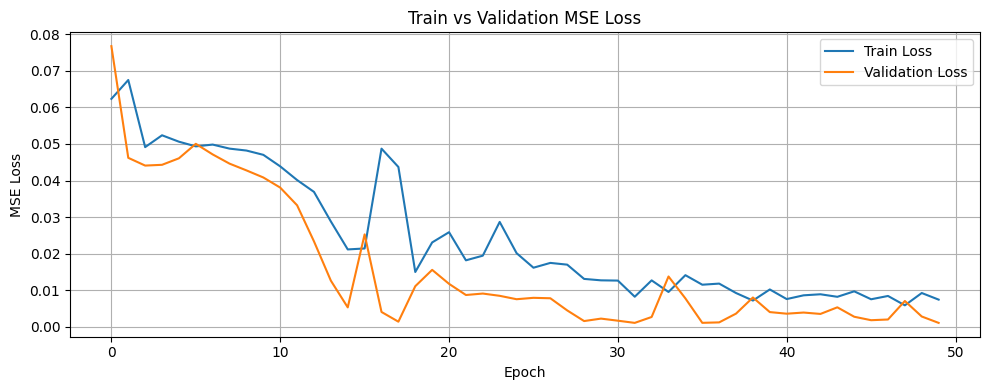

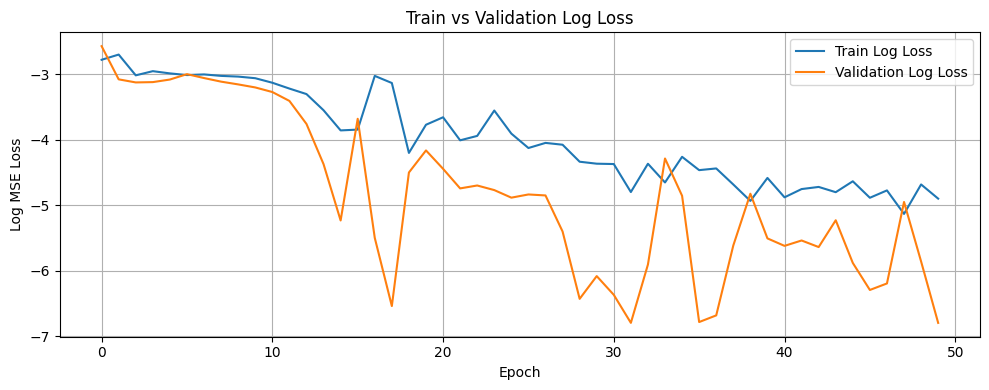

Training completed
Making predictions for 15 rows...
Error during scaling: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were in fit.

344471.58521413803
Error during scaling: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were in fit.

368563.8288259506
Found new category in remaining_lease. Using default encoding.
New categories in remaining_lease (using default encoding): ['41 years']
Error during scaling: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were in fit.

349809.11388993263
Error during scaling: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were in fit.

363565.5454993248
Error during scaling: The feature names should match those that were passed during fit.
Feature names must be in the same order as they w

In [29]:
#run the model
results = run_model_on_2025(df)

Plotting histograms for 6 valid predictions


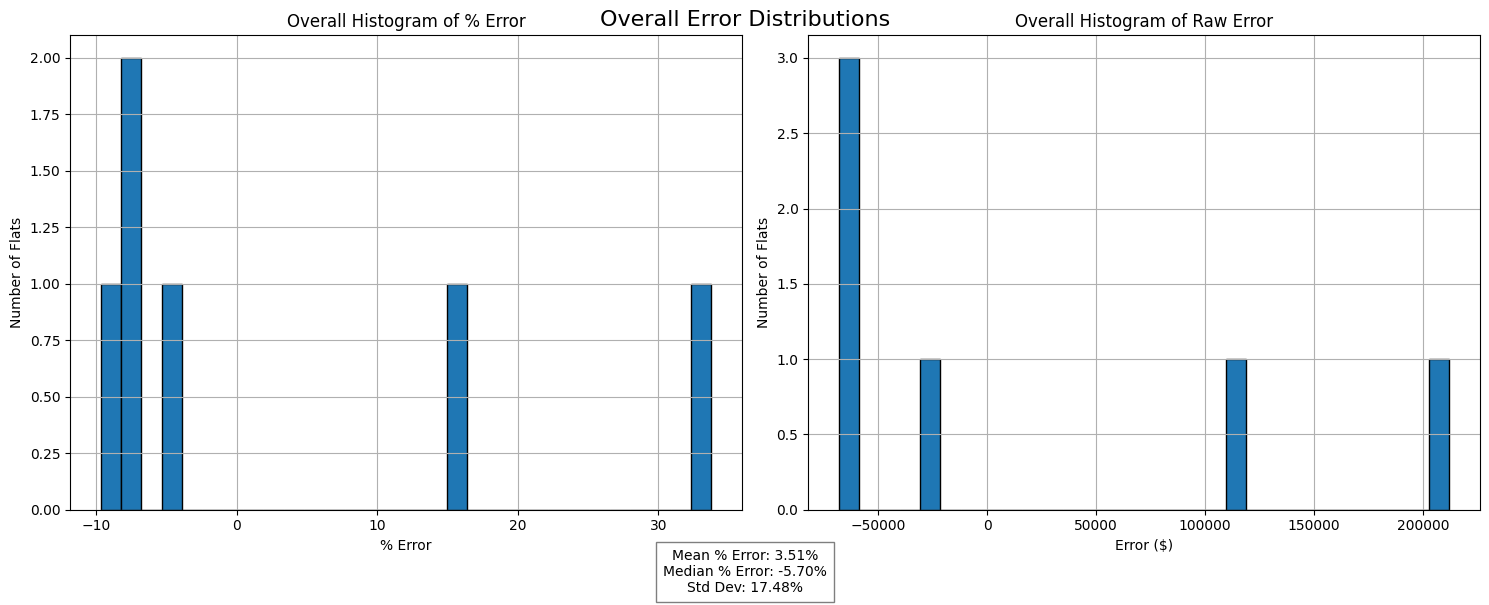

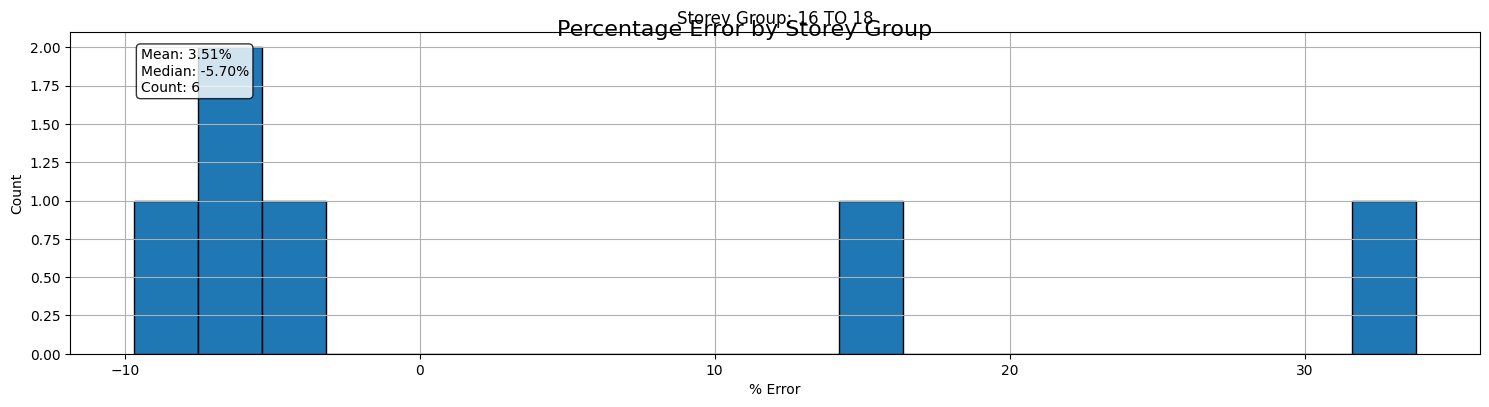

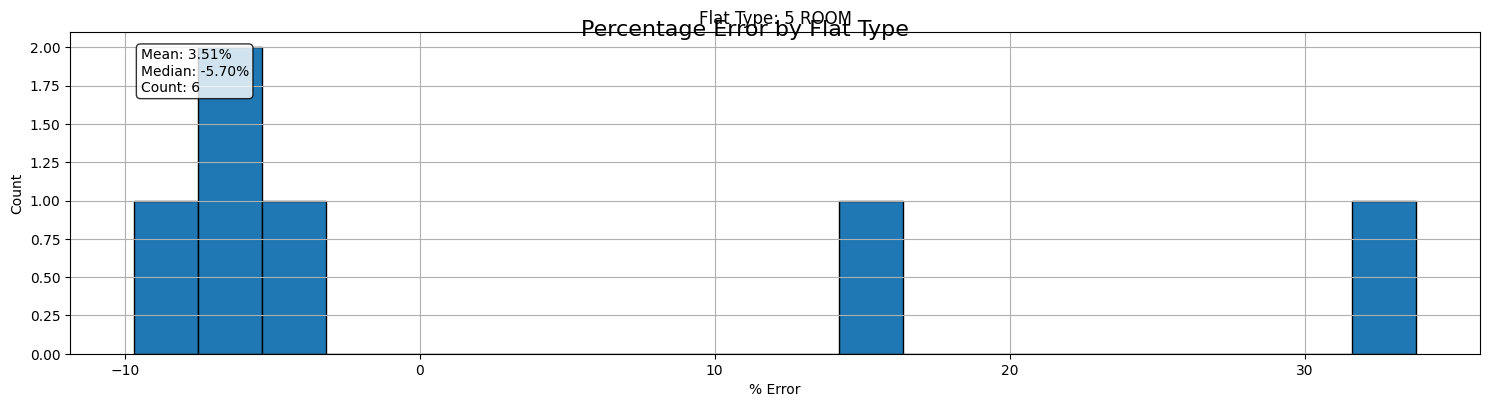

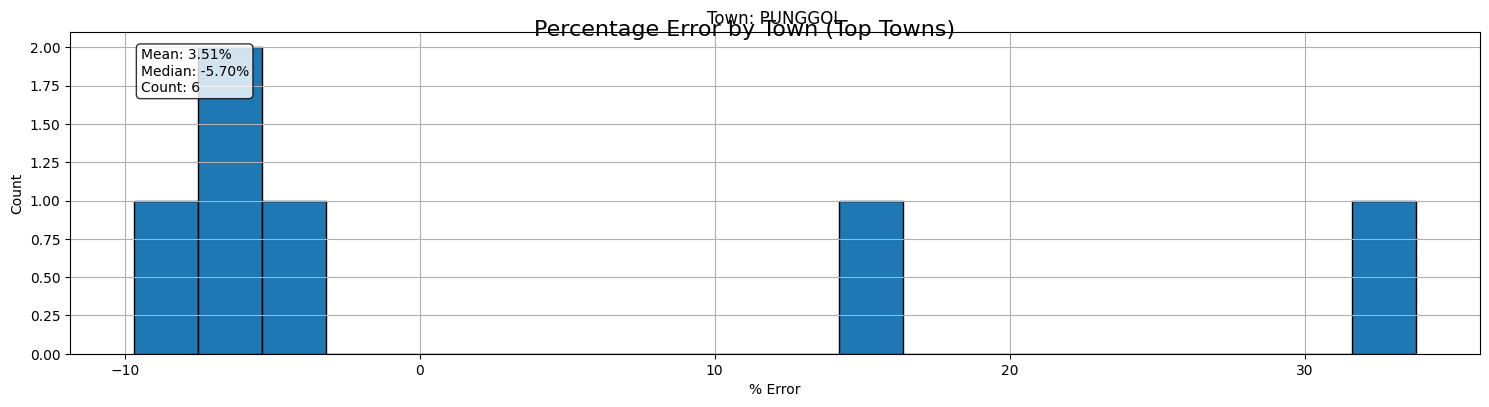


Overall Summary Statistics:
Mean Percent Error: 3.51%
Median Percent Error: -5.70%
Standard Deviation: 17.48%

Summary by Storey Group:
             percent_error                                  error  \
                      mean   median        std count         mean   
storey_range                                                        
16 TO 18          3.509556 -5.69595  17.477205     6  16390.64109   

                                           
                    median            std  
storey_range                               
16 TO 18     -45255.302753  117526.768282  

Summary by Flat Type:
          percent_error                                  error                \
                   mean   median        std count         mean        median   
flat_type                                                                      
5 ROOM         3.509556 -5.69595  17.477205     6  16390.64109 -45255.302753   

                          
                     std  
flat_type   

,index,town,flat_type,storey_range,actual_price,predicted_price,error,percent_error
0,199978,PUNGGOL,5 ROOM,16 TO 18,668000.0,637315.727808,-30684.272192,-4.593454
1,199997,PUNGGOL,5 ROOM,16 TO 18,895000.0,829503.074378,-65496.925622,-7.318092
2,200011,PUNGGOL,5 ROOM,16 TO 18,705000.0,815496.021330,110496.021330,15.673195
3,200018,PUNGGOL,5 ROOM,16 TO 18,628000.0,840119.529784,212119.529784,33.776995
4,200020,PUNGGOL,5 ROOM,16 TO 18,705000.0,636735.826552,-68264.173448,-9.682861
5,200042,PUNGGOL,5 ROOM,16 TO 18,880000.0,820173.666686,-59826.333314,-6.798447


In [19]:
#display results
plot_error_histograms(results)

testing to be deleted
